# Compare classification models

In [1]:
import copy
import hashlib
import os
from pathlib import Path

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from catboost import CatBoostClassifier, Pool
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from tabm import TabM
from xgboost import XGBClassifier, callback

## Load the data

In [2]:
PROJECT_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / "data" / "capslpdb" / "recordings.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

SPLIT_DIR = PROJECT_ROOT / "outputs" / "splits"
RANDOM_SEED = 42
MAX_EPOCHS = 500
PATIENCE = 30
LOG_EVERY = 10
TREES_PER_STEP = 10
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
os.environ.setdefault("TABPFN_MODEL_CACHE_DIR", str(PROJECT_ROOT / "data" / "models" / "tabpfn"))
os.environ.setdefault("TABPFN_NO_BROWSER", "1")
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

signals = ["eeg_delta_power", "eeg_theta_power", "eeg_alpha_power", "eeg_beta_power", "eog_sd_uv", "emg_rms_uv"]
features = [f"{signal}_{statistic}" for signal in signals for statistic in ("median", "p90")]
train = pd.read_csv(SPLIT_DIR / "train.csv")
validation = pd.read_csv(SPLIT_DIR / "validation.csv")

def check_split(table):
    if not set(["record_id", "class_name", *features]).issubset(table.columns):
        raise ValueError("A split is missing recording IDs, labels or features.")
    if table["record_id"].isna().any() or table["record_id"].duplicated().any():
        raise ValueError("Each recording needs a unique ID.")
    if set(table["class_name"]) != {"healthy", "other", "rbd"}:
        raise ValueError("Each split must contain all three classes.")
    if not np.isfinite(table[features].to_numpy(dtype=float)).all():
        raise ValueError("The features contain missing or non-finite values.")

check_split(train)
check_split(validation)
if set(train["record_id"]) & set(validation["record_id"]):
    raise ValueError("Training and validation contain the same recording.")

label_encoder = LabelEncoder().fit(train["class_name"])
X_train, y_train = train[features], label_encoder.transform(train["class_name"])
X_validation, y_validation = validation[features], label_encoder.transform(validation["class_name"])
class_counts = pd.DataFrame({"train": train.groupby("class_name").size(),
                             "validation": validation.groupby("class_name").size()})
class_counts["validation_loss_weight"] = len(validation) / (len(label_encoder.classes_) * class_counts["validation"])
display(class_counts.round(3))

,train,validation,validation_loss_weight
class_name,,,
healthy,9,2,1.833
other,41,7,0.524
rbd,13,2,1.833


## Define the training

Balance the training samples and weight each validation class equally.

In [3]:
def balanced_indices(y, rng):
    groups = [np.flatnonzero(y == label) for label in np.unique(y)]
    largest = max(len(group) for group in groups)
    sampled = [rng.choice(group, size=largest, replace=len(group) < largest) for group in groups]
    return rng.permutation(np.concatenate(sampled))

def balanced_loss(y, probabilities):
    weights = compute_sample_weight("balanced", y)
    return log_loss(y, probabilities, labels=np.arange(len(label_encoder.classes_)), sample_weight=weights)

def record_step(history, step, train_loss, validation_loss, unit="Epoch"):
    history.append({"step": step, "train_loss": train_loss, "validation_loss": validation_loss})
    if step == 1 or step % LOG_EVERY == 0:
        print(f"{unit} {step:03d} | balanced train log loss: {train_loss:.4f} | balanced validation log loss: {validation_loss:.4f}")

class EarlyStopping:
    def __init__(self):
        self.best_loss = float("inf")
        self.best_step = 0
        self.best_model = None
        self.wait = 0

    def update(self, step, loss, model):
        if loss < self.best_loss:
            self.best_loss = loss
            self.best_step = step
            self.best_model = copy.deepcopy(model)
            self.wait = 0
        else:
            self.wait += 1
        return self.wait >= PATIENCE

def train_logistic():
    scaler = StandardScaler().fit(X_train)
    x_train = scaler.transform(X_train)
    x_validation = scaler.transform(X_validation)
    model = SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01,
                          alpha=0.0001, shuffle=False, random_state=RANDOM_SEED)
    rng = np.random.default_rng(RANDOM_SEED)
    stopper, history = EarlyStopping(), []
    for epoch in range(1, MAX_EPOCHS + 1):
        indices = balanced_indices(y_train, rng)
        model.partial_fit(x_train[indices], y_train[indices], classes=np.arange(len(label_encoder.classes_)))
        train_loss = balanced_loss(y_train, model.predict_proba(x_train))
        validation_loss = balanced_loss(y_validation, model.predict_proba(x_validation))
        record_step(history, epoch, train_loss, validation_loss)
        if stopper.update(epoch, validation_loss, model):
            break
    print(f"Best epoch: {stopper.best_step} | balanced validation log loss: {stopper.best_loss:.4f}")
    return make_pipeline(scaler, stopper.best_model), history, stopper.best_step

class TabMClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, seed=42):
        self.seed = seed

    def fit(self, X, y, X_validation, y_validation):
        torch.manual_seed(self.seed)
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.scaler_ = StandardScaler().fit(X)
        x = torch.tensor(self.scaler_.transform(X), dtype=torch.float32)
        x_validation = torch.tensor(self.scaler_.transform(X_validation), dtype=torch.float32)
        target = torch.tensor(encoded, dtype=torch.long)
        self.model_ = TabM.make(n_num_features=x.shape[1], d_out=len(self.classes_),
                                n_blocks=2, d_block=64, dropout=0.1, k=16)
        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=0.001, weight_decay=0.0001)
        rng = np.random.default_rng(self.seed)
        stopper, self.history_ = EarlyStopping(), []
        for epoch in range(1, MAX_EPOCHS + 1):
            indices = balanced_indices(encoded, rng)
            self.model_.train()
            optimizer.zero_grad()
            logits = self.model_(x[indices])
            loss = F.cross_entropy(logits.reshape(-1, len(self.classes_)),
                                   target[indices].repeat_interleave(self.model_.k))
            loss.backward()
            optimizer.step()
            self.model_.eval()
            with torch.no_grad():
                train_proba = self.model_(x).softmax(dim=-1).mean(dim=1).numpy()
                validation_proba = self.model_(x_validation).softmax(dim=-1).mean(dim=1).numpy()
            train_loss = balanced_loss(y, train_proba)
            validation_loss = balanced_loss(y_validation, validation_proba)
            record_step(self.history_, epoch, train_loss, validation_loss)
            if stopper.update(epoch, validation_loss, self.model_):
                break
        self.model_, self.best_step_ = stopper.best_model, stopper.best_step
        print(f"Best epoch: {stopper.best_step} | balanced validation log loss: {stopper.best_loss:.4f}")
        return self

    def predict_proba(self, X):
        self.model_.eval()
        with torch.no_grad():
            x = torch.tensor(self.scaler_.transform(X), dtype=torch.float32)
            return self.model_(x).softmax(dim=-1).mean(dim=1).numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

def train_tabm():
    model = TabMClassifier(seed=RANDOM_SEED).fit(X_train, y_train, X_validation, y_validation)
    return model, model.history_, model.best_step_

def train_random_forest():
    model = RandomForestClassifier(n_estimators=TREES_PER_STEP, warm_start=True, min_samples_leaf=2,
                                   random_state=RANDOM_SEED, n_jobs=1)
    stopper, history = EarlyStopping(), []
    for trees in range(TREES_PER_STEP, MAX_EPOCHS + 1, TREES_PER_STEP):
        model.set_params(n_estimators=trees)
        model.fit(X_balanced, y_balanced)
        train_loss = balanced_loss(y_train, model.predict_proba(X_train))
        validation_loss = balanced_loss(y_validation, model.predict_proba(X_validation))
        record_step(history, trees, train_loss, validation_loss, unit="Trees")
        if stopper.update(trees, validation_loss, model):
            break
    print(f"Best number of trees: {stopper.best_step} | balanced validation log loss: {stopper.best_loss:.4f}")
    return stopper.best_model, history, stopper.best_step

def train_xgboost():
    print("Validation metric: class-balanced log loss")
    model = XGBClassifier(n_estimators=MAX_EPOCHS, max_depth=3, learning_rate=0.05, reg_lambda=3,
                          objective="multi:softprob", num_class=len(label_encoder.classes_),
                          eval_metric="mlogloss",
                          callbacks=[callback.EarlyStopping(rounds=PATIENCE, metric_name="mlogloss",
                                                            data_name="validation_1", maximize=False, save_best=True)],
                          random_state=RANDOM_SEED, n_jobs=1)
    model.fit(X_balanced, y_balanced, eval_set=[(X_balanced, y_balanced), (X_validation, y_validation)],
              sample_weight_eval_set=[np.ones(len(y_balanced)), compute_sample_weight("balanced", y_validation)],
              verbose=LOG_EVERY)
    scores = model.evals_result()
    history = [{"step": index + 1, "train_loss": train_loss, "validation_loss": validation_loss}
               for index, (train_loss, validation_loss) in enumerate(zip(scores["validation_0"]["mlogloss"], scores["validation_1"]["mlogloss"]))]
    best_step = model.best_iteration + 1
    print(f"Best boosting round: {best_step} | balanced validation log loss: {model.best_score:.4f}")
    return model, history, best_step

def train_catboost():
    print("Validation metric: class-balanced log loss")
    model = CatBoostClassifier(iterations=MAX_EPOCHS, depth=3, learning_rate=0.05,
                               loss_function="MultiClass", random_seed=RANDOM_SEED,
                               thread_count=1, verbose=LOG_EVERY, allow_writing_files=False)
    validation_pool = Pool(X_validation, y_validation, weight=compute_sample_weight("balanced", y_validation))
    model.fit(X_balanced, y_balanced, eval_set=validation_pool,
              early_stopping_rounds=PATIENCE, use_best_model=True)
    scores = model.get_evals_result()
    history = [{"step": index + 1, "train_loss": train_loss, "validation_loss": validation_loss}
               for index, (train_loss, validation_loss) in enumerate(zip(scores["learn"]["MultiClass"], scores["validation"]["MultiClass"]))]
    best_step = model.get_best_iteration() + 1
    print(f"Best boosting round: {best_step} | balanced validation log loss: {min(scores['validation']['MultiClass']):.4f}")
    return model, history, best_step

def train_once(model, balanced=True, description="Single fit"):
    X, y = (X_balanced, y_balanced) if balanced else (X_train, y_train)
    model.fit(X, y)
    train_loss = balanced_loss(y_train, model.predict_proba(X_train))
    validation_loss = balanced_loss(y_validation, model.predict_proba(X_validation))
    print(f"{description} | balanced train log loss: {train_loss:.4f} | balanced validation log loss: {validation_loss:.4f}")
    return model, [{"step": 1, "train_loss": train_loss, "validation_loss": validation_loss}], 1

def train_svm():
    model = make_pipeline(StandardScaler(), SVC(C=1, random_state=RANDOM_SEED))
    model.fit(X_balanced, y_balanced)
    print("Single fit | probability-based log loss is not available for this SVM")
    return model, [], None

trainers = {
    "Majority baseline": lambda: train_once(DummyClassifier(strategy="most_frequent"), balanced=False),
    "Logistic regression": train_logistic,
    "RBF SVM": train_svm,
    "Random forest": train_random_forest,
    "XGBoost": train_xgboost,
    "CatBoost": train_catboost,
    "TabPFN v2": lambda: train_once(TabPFNClassifier.create_default_for_version(ModelVersion.V2, device="cpu", n_estimators=4, random_state=RANDOM_SEED), description="Pretrained model conditioned on training data"),
    "TabM": train_tabm,
}

## Training

Use class-balanced validation log loss for early stopping where supported.

In [4]:
indices = balanced_indices(y_train, np.random.default_rng(RANDOM_SEED))
X_balanced, y_balanced = X_train.iloc[indices], y_train[indices]
display(pd.Series(y_balanced).map(dict(enumerate(label_encoder.classes_))).value_counts().rename("balanced_samples").to_frame())

training_modes = {"Majority baseline": "baseline", "Logistic regression": "epochs",
                  "RBF SVM": "single fit", "Random forest": "trees",
                  "XGBoost": "boosting rounds", "CatBoost": "boosting rounds",
                  "TabPFN v2": "pretrained", "TabM": "epochs"}
trained_models, training_history, best_steps, summaries = {}, {}, {}, []
for name, trainer in trainers.items():
    print(f"\n{name}")
    model, history, best_step = trainer()
    trained_models[name], training_history[name], best_steps[name] = model, history, best_step
    prediction = model.predict(X_validation)
    validation_loss = balanced_loss(y_validation, model.predict_proba(X_validation)) if name != "RBF SVM" else np.nan
    summaries.append({"model": name, "training_mode": training_modes[name],
                      "best_step": best_step if len(history) > 1 else "N/A",
                      "balanced_validation_log_loss": validation_loss,
                      "validation_macro_f1": f1_score(y_validation, prediction, average="macro", zero_division=0),
                      "validation_balanced_accuracy": balanced_accuracy_score(y_validation, prediction)})

training_summary = pd.DataFrame(summaries)
display(training_summary.style.format({"balanced_validation_log_loss": "{:.4f}", "validation_macro_f1": "{:.3f}",
                                       "validation_balanced_accuracy": "{:.3f}"}, na_rep="N/A"))
model_file = PROJECT_ROOT / "outputs" / "models" / "classifiers.pkl"
model_file.parent.mkdir(parents=True, exist_ok=True)
bundle = {
    "models": trained_models,
    "features": features,
    "classes": label_encoder.classes_.tolist(),
    "training_history": training_history,
    "best_steps": best_steps,
    "training_settings": {"seed": RANDOM_SEED, "max_epochs": MAX_EPOCHS,
                          "patience": PATIENCE, "trees_per_step": TREES_PER_STEP},
    "train_ids": train["record_id"].tolist(),
    "validation_ids": validation["record_id"].tolist(),
    "train_hash": hashlib.sha256((SPLIT_DIR / "train.csv").read_bytes()).hexdigest(),
    "validation_hash": hashlib.sha256((SPLIT_DIR / "validation.csv").read_bytes()).hexdigest(),
}
temporary = model_file.with_suffix(".tmp")
with temporary.open("wb") as file:
    cloudpickle.dump(bundle, file)
temporary.replace(model_file)
print(f"Saved {len(trained_models)} models to {model_file.relative_to(PROJECT_ROOT).as_posix()}.")

,balanced_samples
other,41
rbd,41
healthy,41



Majority baseline
Single fit | balanced train log loss: 24.0291 | balanced validation log loss: 24.0291

Logistic regression
Epoch 001 | balanced train log loss: 0.9851 | balanced validation log loss: 1.0322
Epoch 010 | balanced train log loss: 0.8895 | balanced validation log loss: 1.1007
Epoch 020 | balanced train log loss: 0.8725 | balanced validation log loss: 1.0371
Epoch 030 | balanced train log loss: 0.8651 | balanced validation log loss: 1.1152
Best epoch: 3 | balanced validation log loss: 1.0025

RBF SVM
Single fit | probability-based log loss is not available for this SVM

Random forest
Trees 010 | balanced train log loss: 0.2155 | balanced validation log loss: 0.9419
Trees 020 | balanced train log loss: 0.2123 | balanced validation log loss: 1.1018
Trees 030 | balanced train log loss: 0.1980 | balanced validation log loss: 1.0605
Trees 040 | balanced train log loss: 0.1955 | balanced validation log loss: 0.9958
Trees 050 | balanced train log loss: 0.1897 | balanced validati

,model,training_mode,best_step,balanced_validation_log_loss,validation_macro_f1,validation_balanced_accuracy
0,Majority baseline,baseline,N/A,24.0291,0.259,0.333
1,Logistic regression,epochs,3,1.0025,0.361,0.548
2,RBF SVM,single fit,N/A,N/A,0.229,0.262
3,Random forest,trees,10,0.9419,0.641,0.619
4,XGBoost,boosting rounds,36,0.9032,0.433,0.452
5,CatBoost,boosting rounds,63,0.9893,0.690,0.738
6,TabPFN v2,pretrained,N/A,1.0465,0.497,0.500
7,TabM,epochs,37,1.0237,0.361,0.548


Saved 8 models to outputs/models/classifiers.pkl.


## Training progress

Compare the class-balanced training and validation log loss for iterative models.

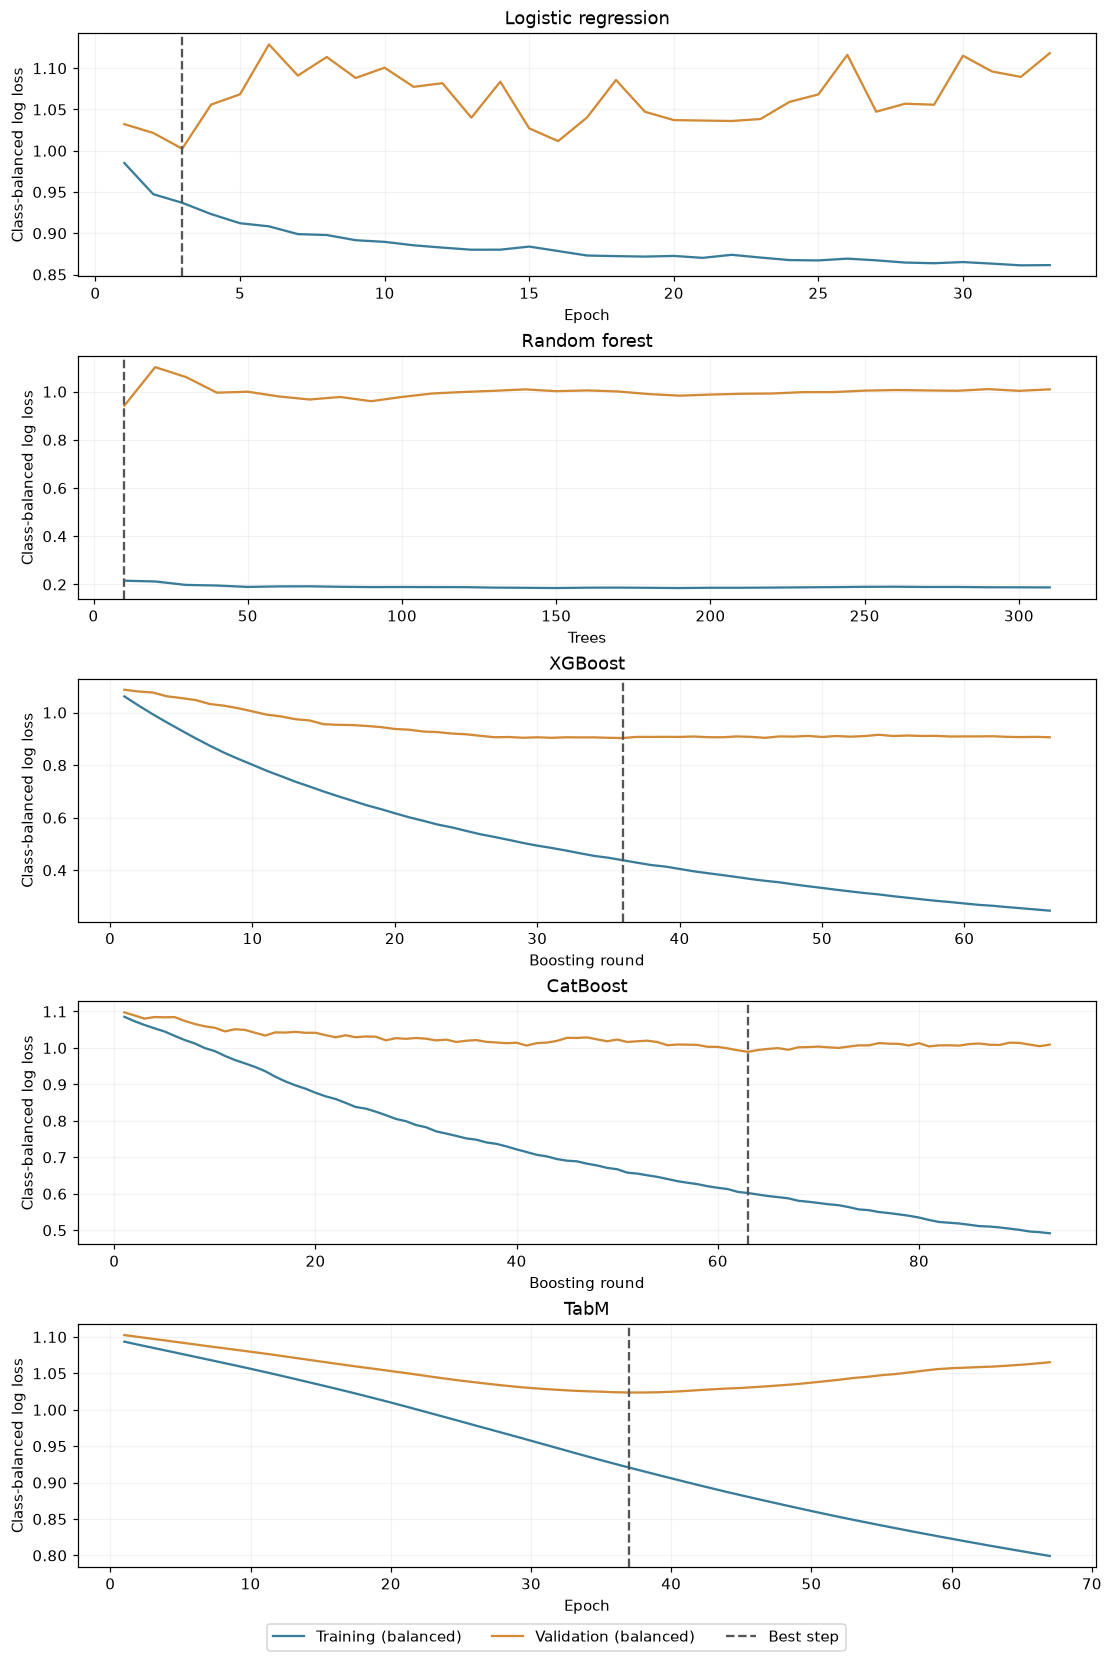

In [5]:
iterative = {name: pd.DataFrame(history) for name, history in training_history.items() if len(history) > 1}
fig, axes = plt.subplots(len(iterative), 1, figsize=(10, 3 * len(iterative)), layout="constrained")
for ax, (name, history) in zip(np.atleast_1d(axes), iterative.items()):
    ax.plot(history["step"], history["train_loss"], label="Training (balanced)", color="#397c99")
    ax.plot(history["step"], history["validation_loss"], label="Validation (balanced)", color="#d18a36")
    ax.axvline(best_steps[name], color="#555555", linestyle="--", label="Best step")
    ax.set(title=name, xlabel="Trees" if name == "Random forest" else "Boosting round" if name in {"XGBoost", "CatBoost"} else "Epoch", ylabel="Class-balanced log loss")
    ax.grid(alpha=0.15)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
plt.show()

## Test

Load the saved models and evaluate them on the test split.

In [ ]:
import hashlib
import os
from pathlib import Path

import cloudpickle
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score

PROJECT_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / "data" / "capslpdb" / "recordings.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")
SPLIT_DIR = PROJECT_ROOT / "outputs" / "splits"
model_file = PROJECT_ROOT / "outputs" / "models" / "classifiers.pkl"
os.environ.setdefault("TABPFN_MODEL_CACHE_DIR", str(PROJECT_ROOT / "data" / "models" / "tabpfn"))
os.environ.setdefault("TABPFN_NO_BROWSER", "1")
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

with model_file.open("rb") as file:
    saved = cloudpickle.load(file)
for name in ("train", "validation"):
    actual = hashlib.sha256((SPLIT_DIR / f"{name}.csv").read_bytes()).hexdigest()
    if actual != saved[f"{name}_hash"]:
        raise ValueError(f"The {name} split changed. Train and save the models again.")

test = pd.read_csv(SPLIT_DIR / "test.csv")
features, classes = saved["features"], saved["classes"]
if not set(["record_id", "class_name", *features]).issubset(test.columns):
    raise ValueError("The test split is missing recording IDs, labels or features.")
if test["record_id"].isna().any() or test["record_id"].duplicated().any():
    raise ValueError("Each test recording needs a unique ID.")
if set(test["record_id"]) & set(saved["train_ids"] + saved["validation_ids"]):
    raise ValueError("The test set overlaps with training or validation.")
if set(test["class_name"]) != set(classes) or not np.isfinite(test[features].to_numpy(dtype=float)).all():
    raise ValueError("The test split contains invalid classes or feature values.")

class_index = {name: index for index, name in enumerate(classes)}
y_test = test["class_name"].map(class_index).to_numpy()
test_predictions = {}
test_results = []
for name, model in saved["models"].items():
    prediction = model.predict(test[features])
    test_predictions[name] = prediction
    recalls = recall_score(y_test, prediction, labels=np.arange(len(classes)), average=None, zero_division=0)
    row = {"model": name, "macro_f1": f1_score(y_test, prediction, average="macro", zero_division=0),
           "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
           "accuracy": accuracy_score(y_test, prediction)}
    row.update({f"{label}_recall": value for label, value in zip(classes, recalls)})
    test_results.append(row)

test_comparison = pd.DataFrame(test_results)
display(test_comparison.style.format({column: "{:.3f}" for column in test_comparison.columns if column != "model"}))